# Tahap 4 KDD - Data Mining (Training)

Melatih **5 model** (KNN, SVM, Random Forest, Extra Trees, Logistic Regression) pada **4 skenario fitur** (A-D) dengan GridSearchCV 5-fold.

Model dipilih berdasarkan **CV F1-macro**, bukan skor test.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path

HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C
print("ROOT:", ROOT)
print("Kelas:", C.CLASSES)

ROOT: D:\Perkuliahan\Machine Learning teori\Ban_Motor
Kelas: ['baik', 'sedang', 'aus']


In [2]:
from src.train_classic import run_training

results, bundle = run_training(verbose=True)
results

[KNN                | A_LBP256 (jurnal) ] CV F1=0.6316 test F1=0.6398 recall aus=0.9286


[SVM                | A_LBP256 (jurnal) ] CV F1=0.6979 test F1=0.6693 recall aus=0.9524


[RandomForest       | A_LBP256 (jurnal) ] CV F1=0.6623 test F1=0.6941 recall aus=0.8810


[ExtraTrees         | A_LBP256 (jurnal) ] CV F1=0.6358 test F1=0.6580 recall aus=0.9286


[LogisticRegression | A_LBP256 (jurnal) ] CV F1=0.6546 test F1=0.6058 recall aus=0.7857


...

[RandomForest       | D_Lengkap         ] CV F1=0.7119 test F1=0.6771 recall aus=0.8571


[ExtraTrees         | D_Lengkap         ] CV F1=0.7116 test F1=0.6775 recall aus=0.9286


[LogisticRegression | D_Lengkap         ] CV F1=0.7324 test F1=0.7482 recall aus=0.8810



Model terbaik (berdasar CV): SVM + D_Lengkap
Detail: {'model': 'SVM', 'feature_set': 'D_Lengkap', 'n_features': 63, 'cv_grid_f1_macro': 0.7687, 'best_params': {'clf__C': '10', 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}, 'filter_method': 'gaussian', 'random_state': 42}


,fitur,model,n_features,cv_grid_f1_macro,cv_repeat_f1_macro_mean,cv_repeat_f1_macro_std,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,...,test_f1_baik,test_precision_sedang,test_recall_sedang,test_f1_sedang,test_precision_aus,test_recall_aus,test_f1_aus,test_roc_auc_ovr_macro,test_log_loss,best_params
16,D_Lengkap,SVM,63,0.7687,0.7474,0.0365,0.7358,0.7091,0.7176,0.7091,...,0.7536,0.5385,0.5385,0.5385,0.7755,0.9048,0.8352,0.8531,0.6853,"{'clf__C': 10, 'clf__gamma': 'scale', 'clf__ke..."
11,C_LBP-MS + arah,SVM,59,0.7560,0.7452,0.0306,0.7358,0.7083,0.7173,0.7083,...,0.7353,0.5385,0.5385,0.5385,0.7800,0.9286,0.8478,0.8463,0.7018,"{'clf__C': 10, 'clf__gamma': 'scale', 'clf__ke..."
6,B_LBP multi-skala,SVM,54,0.7487,0.7371,0.0538,0.7453,0.7162,0.7247,0.7162,...,0.7246,0.5833,0.5385,0.5600,0.7843,0.9524,0.8602,0.8384,0.7198,"{'clf__C': 10, 'clf__gamma': 0.01, 'clf__kerne..."
19,D_Lengkap,LogisticRegression,63,0.7350,0.7324,0.0339,0.7642,0.7525,0.7520,0.7525,...,0.7429,0.5625,0.6923,0.6207,0.8810,0.8810,0.8810,0.8869,0.6558,{'clf__C': 1}
9,B_LBP multi-skala,LogisticRegression,54,0.7224,0.7208,0.0472,0.7453,0.7349,0.7374,0.7349,...,0.7164,0.5625,0.6923,0.6207,0.8222,0.8810,0.8506,0.8760,0.6631,{'clf__C': 0.1}
14,C_LBP-MS + arah,LogisticRegression,59,0.7211,0.7198,0.0312,0.7642,0.7565,0.7565,0.7565,...,0.7353,0.5758,0.7308,0.6441,0.8605,0.8810,0.8706,0.8769,0.6750,{'clf__C': 1}
12,C_LBP-MS + arah,RandomForest,59,0.7266,0.7148,0.0483,0.7170,0.6924,0.6961,0.6924,...,0.7042,0.5600,0.5385,0.5490,0.7708,0.8810,0.8222,0.8555,0.7042,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
17,D_Lengkap,RandomForest,63,0.7238,0.7119,0.0456,0.6981,0.6798,0.6812,0.6798,...,0.6667,0.5357,0.5769,0.5556,0.7660,0.8571,0.8090,0.8510,0.7222,"{'clf__max_depth': None, 'clf__n_estimators': ..."
18,D_Lengkap,ExtraTrees,63,0.7230,0.7116,0.0410,0.7170,0.6786,0.6944,0.6786,...,0.7027,0.6111,0.4231,0.5000,0.7500,0.9286,0.8298,0.8475,0.7096,"{'clf__max_depth': 20, 'clf__n_estimators': 400}"
7,B_LBP multi-skala,RandomForest,54,0.7240,0.7092,0.0392,0.7264,0.7061,0.7068,0.7061,...,0.7222,0.5556,0.5769,0.5660,0.8000,0.8571,0.8276,0.8490,0.7258,"{'clf__max_depth': 10, 'clf__n_estimators': 400}"


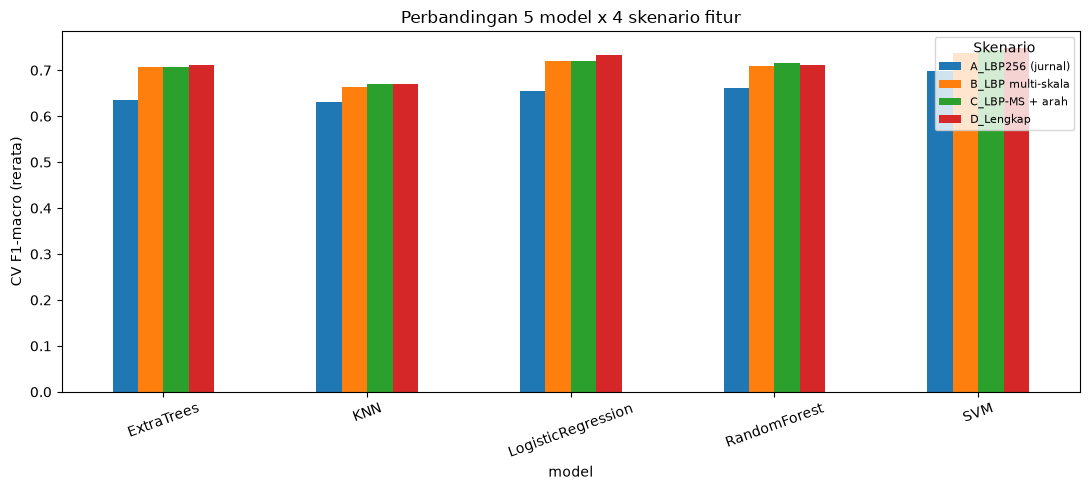

Model terbaik: SVM + D_Lengkap


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(C.TAB_DIR / "perbandingan_model.csv")
pivot = df.pivot(index="model", columns="fitur", values="cv_repeat_f1_macro_mean")
pivot.plot(kind="bar", figsize=(11, 5), rot=20)
plt.ylabel("CV F1-macro (rerata)")
plt.title("Perbandingan 5 model x 4 skenario fitur")
plt.legend(title="Skenario", fontsize=8)
plt.tight_layout()
plt.show()

print("Model terbaik:", bundle["name"], "+", bundle["feature_set"])